In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

In [6]:
df = pd.read_csv("/content/rfm_scores.csv")

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())

Dataset shape: (5878, 9)

Columns: ['CustomerID', 'recency', 'frequency', 'monetary', 'r_score', 'f_score', 'm_score', 'total_rfm_score', 'rfm_combined']


,CustomerID,recency,frequency,monetary,r_score,f_score,m_score,total_rfm_score,rfm_combined
0,13119,669,1,134.90,1,1,1,3,111
1,15317,678,1,129.75,1,1,1,3,111
2,18238,516,1,270.92,1,1,1,3,111
3,16047,683,1,107.14,1,1,1,3,111
4,16417,493,1,35.70,1,1,1,3,111


In [7]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["CustomerID"].duplicated().sum())

print("\nRFM summary:")
display(df[["recency", "frequency", "monetary"]].describe())

Data types:
CustomerID           int64
recency              int64
frequency            int64
monetary           float64
r_score              int64
f_score              int64
m_score              int64
total_rfm_score      int64
rfm_combined         int64
dtype: object

Missing values:
CustomerID         0
recency            0
frequency          0
monetary           0
r_score            0
f_score            0
m_score            0
total_rfm_score    0
rfm_combined       0
dtype: int64

Duplicate rows: 0
Duplicate customer IDs: 0

RFM summary:


,recency,frequency,monetary
count,5878.000000,5878.000000,5878.000000
mean,201.866791,6.289384,3018.616734
std,209.353961,13.009406,14737.731038
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,348.762500
50%,96.000000,3.000000,898.915000
75%,380.000000,7.000000,2307.090000
max,739.000000,398.000000,608821.650000


In [8]:
rfm = df[["CustomerID", "recency", "frequency", "monetary"]].copy()

In [9]:
rfm_columns = ["recency", "frequency", "monetary"]

In [10]:
rfm_log = np.log1p(rfm[rfm_columns])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Customers retained:", len(rfm))
print("Feature matrix shape:", X_scaled.shape)

Customers retained: 5878
Feature matrix shape: (5878, 3)


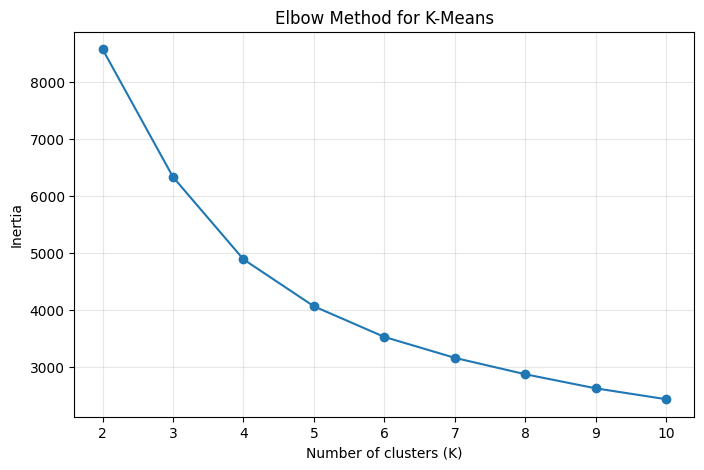

In [11]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

,K,Silhouette Score,Inertia
0,2,0.4381,8576.4342
1,3,0.3480,6335.5137
2,4,0.3667,4893.1076
3,5,0.3427,4069.7931
4,6,0.3325,3533.2613
5,7,0.3127,3166.3956
6,8,0.2970,2879.1468
7,9,0.2893,2632.2272
8,10,0.2905,2441.4347


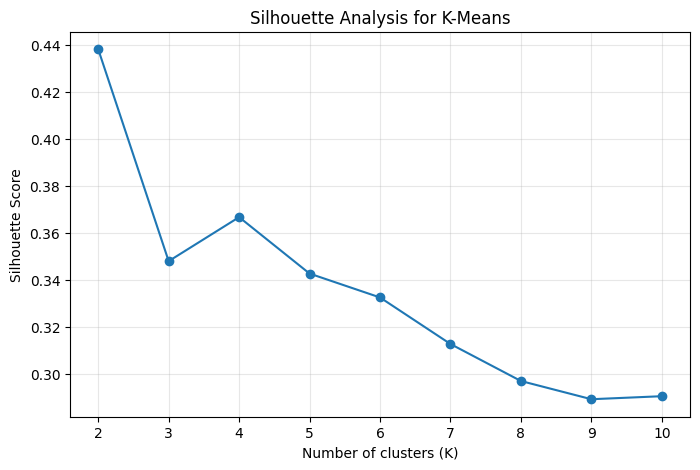

In [12]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score,
        "Inertia": model.inertia_
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
#from the analysis made on the basis of above 2 graphs, k=4 seems reasonable

chosen_k = 4

print("Initial K selected by silhouette:", chosen_k)

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

rfm["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

print("\nCluster sizes:")
print(rfm["kmeans_cluster"].value_counts().sort_index())

print(
    "\nFinal silhouette score:",
    round(silhouette_score(X_scaled, rfm["kmeans_cluster"]), 4)
)

Initial K selected by silhouette: 4

Cluster sizes:
kmeans_cluster
0    1965
1    1195
2    1455
3    1263
Name: count, dtype: int64

Final silhouette score: 0.3667


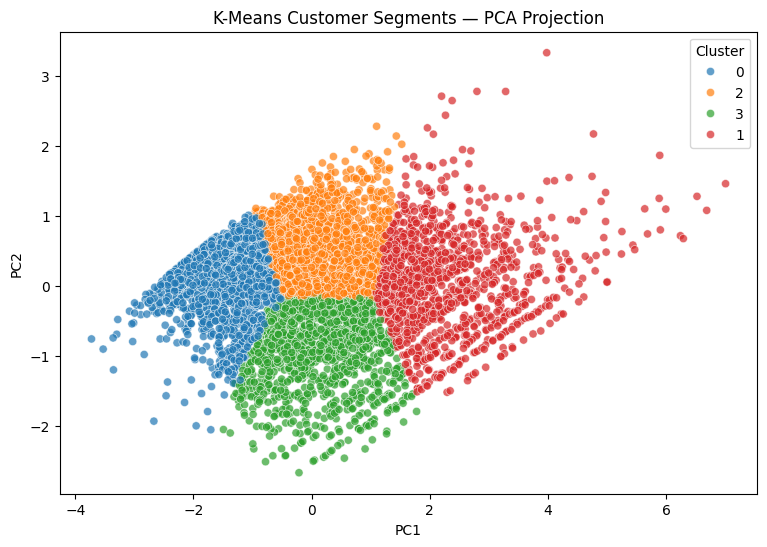

Explained variance ratio: [0.76404863 0.18731161]
Total variance represented: 0.9514


In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": rfm["kmeans_cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=35
)
plt.title("K-Means Customer Segments — PCA Projection")
plt.legend(title="Cluster")
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance represented:", round(pca.explained_variance_ratio_.sum(), 4))

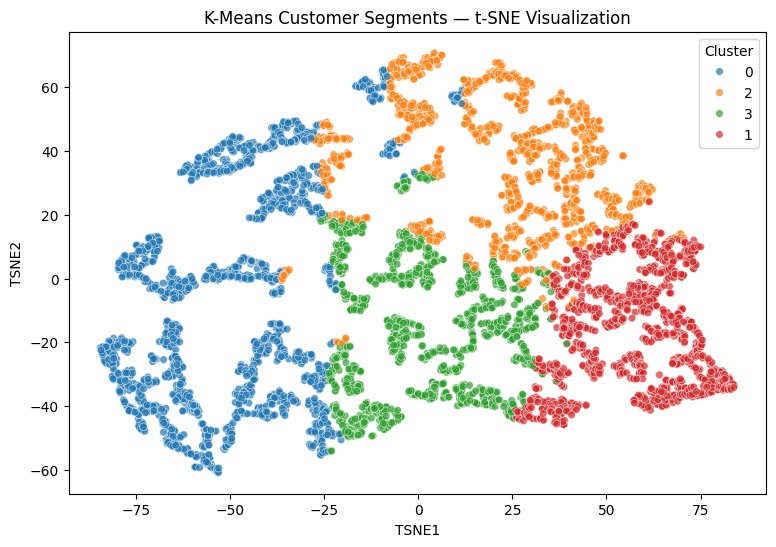

In [19]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame({
    "TSNE1": X_tsne[:, 0],
    "TSNE2": X_tsne[:, 1],
    "Cluster": rfm["kmeans_cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=30
)
plt.title("K-Means Customer Segments — t-SNE Visualization")
plt.legend(title="Cluster")
plt.show()

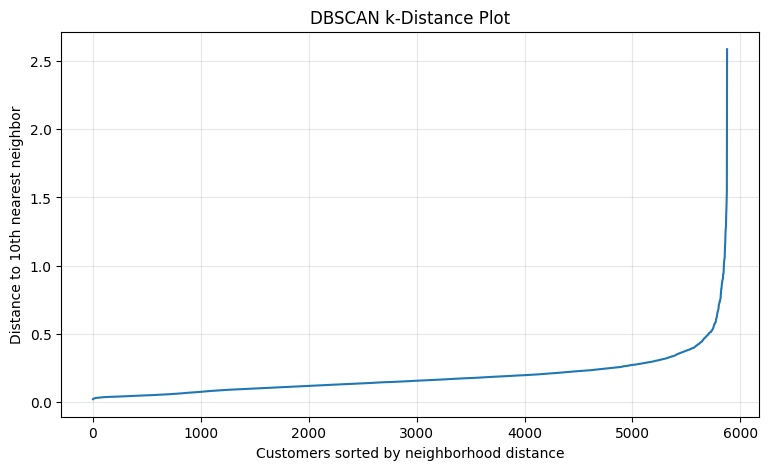

In [20]:
min_samples_guess = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples_guess
)
neighbors.fit(X_scaled)

distances, _ = neighbors.kneighbors(X_scaled)

# Distance to the kth nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Customers sorted by neighborhood distance")
plt.ylabel(f"Distance to {min_samples_guess}th nearest neighbor")
plt.title("DBSCAN k-Distance Plot")
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
eps_candidates = np.unique(
    np.quantile(
        k_distances,
        [0.90, 0.925, 0.95, 0.975, 0.99]
    ).round(3)
)

min_samples_candidates = [5, 10, 15]

dbscan_results = []

for min_samples in min_samples_candidates:
    for eps in eps_candidates:
        model = DBSCAN(
            eps=float(eps),
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        non_noise = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_fraction = np.mean(~non_noise)

        # Evaluate silhouette only if at least 2 clusters remain
        # among non-noise customers.
        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            score = silhouette_score(
                X_scaled[non_noise],
                labels[non_noise]
            )
        else:
            score = np.nan

        dbscan_results.append({
            "eps": float(eps),
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_fraction": noise_fraction,
            "silhouette_non_noise": score
        })

dbscan_df = pd.DataFrame(dbscan_results)

display(
    dbscan_df.sort_values(
        "silhouette_non_noise",
        ascending=False,
        na_position="last"
    ).round(4)
)

,eps,min_samples,n_clusters,noise_fraction,silhouette_non_noise
11,0.359,15,2,0.0459,0.2876
12,0.408,15,2,0.0333,0.2836
1,0.359,5,2,0.0231,0.2813
7,0.408,10,2,0.0235,0.2809
2,0.408,5,3,0.0162,0.2394
6,0.359,10,3,0.0374,0.2147
10,0.317,15,3,0.0692,0.1646
5,0.317,10,3,0.0500,0.1627
0,0.317,5,3,0.0328,0.1584
3,0.519,5,1,0.0088,NaN


In [22]:
valid_dbscan = dbscan_df[
    (dbscan_df["n_clusters"] >= 2)
    & (dbscan_df["noise_fraction"] <= 0.50)
    & (dbscan_df["silhouette_non_noise"].notna())
]

if valid_dbscan.empty:
    print(
        "No DBSCAN candidate met the criteria. "
        "Inspect dbscan_df and expand the eps search."
    )
else:
    best = valid_dbscan.loc[
        valid_dbscan["silhouette_non_noise"].idxmax()
    ]

    best_eps = float(best["eps"])
    best_min_samples = int(best["min_samples"])

    dbscan = DBSCAN(
        eps=best_eps,
        min_samples=best_min_samples
    )

    rfm["dbscan_cluster"] = dbscan.fit_predict(X_scaled)

    print("Chosen eps:", best_eps)
    print("Chosen min_samples:", best_min_samples)
    print("\nCluster sizes, including noise:")
    print(rfm["dbscan_cluster"].value_counts().sort_index())

    print(
        "\nNoise percentage:",
        round((rfm["dbscan_cluster"] == -1).mean() * 100, 2),
        "%"
    )

Chosen eps: 0.359
Chosen min_samples: 15

Cluster sizes, including noise:
dbscan_cluster
-1     270
 0    1577
 1    4031
Name: count, dtype: int64

Noise percentage: 4.59 %


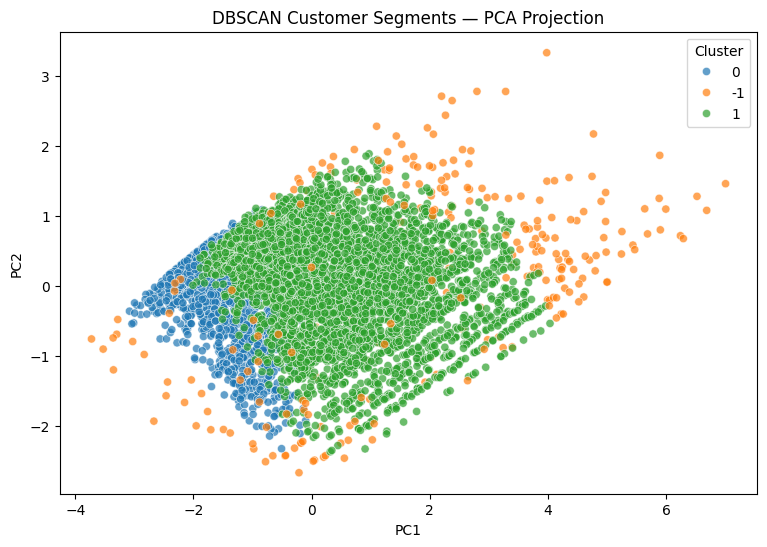

In [23]:
if "dbscan_cluster" in rfm.columns:
    pca_dbscan_df = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "Cluster": rfm["dbscan_cluster"].astype(str).values
    })

    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=pca_dbscan_df,
        x="PC1",
        y="PC2",
        hue="Cluster",
        palette="tab10",
        alpha=0.7,
        s=35
    )
    plt.title("DBSCAN Customer Segments — PCA Projection")
    plt.legend(title="Cluster")
    plt.show()

In [24]:
print("K-Means:")
print("Number of clusters:", rfm["kmeans_cluster"].nunique())
print(
    "Silhouette:",
    round(silhouette_score(X_scaled, rfm["kmeans_cluster"]), 4)
)

if "dbscan_cluster" in rfm.columns:
    db_labels = rfm["dbscan_cluster"].values
    non_noise = db_labels != -1
    n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)

    print("\nDBSCAN:")
    print("Number of clusters:", n_db_clusters)
    print("Noise percentage:", round((~non_noise).mean() * 100, 2), "%")

    if n_db_clusters >= 2 and non_noise.sum() > n_db_clusters:
        db_silhouette = silhouette_score(
            X_scaled[non_noise],
            db_labels[non_noise]
        )
        print(
            "Silhouette excluding noise:",
            round(db_silhouette, 4)
        )
    else:
        print("Silhouette unavailable: fewer than 2 non-noise clusters.")

K-Means:
Number of clusters: 4
Silhouette: 0.3667

DBSCAN:
Number of clusters: 2
Noise percentage: 4.59 %
Silhouette excluding noise: 0.2876


In [25]:
cluster_profile = (
    rfm.groupby("kmeans_cluster")
    .agg(
        customers=("CustomerID", "count"),
        avg_recency=("recency", "mean"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median")
    )
    .round(2)
)

cluster_profile["customer_percentage"] = (
    cluster_profile["customers"] / len(rfm) * 100
).round(2)

display(cluster_profile)

,customers,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,customer_percentage
kmeans_cluster,,,,,,,,
0,1965,397.93,405.0,1.38,1.0,325.51,282.79,33.43
1,1195,28.04,17.0,19.27,13.0,10970.77,5120.00,20.33
2,1455,229.58,186.0,5.09,5.0,1997.27,1508.18,24.75
3,1263,29.37,25.0,3.03,3.0,861.21,742.19,21.49


In [26]:
overall_medians = rfm[rfm_columns].median()

personas = []

for cluster_id, row in cluster_profile.iterrows():
    recency = row["median_recency"]
    frequency = row["median_frequency"]
    monetary = row["median_monetary"]

    recent = recency <= overall_medians["recency"]
    frequent = frequency >= overall_medians["frequency"]
    high_spend = monetary >= overall_medians["monetary"]

    if recent and frequent and high_spend:
        persona = "Champions / High-value loyalists"
        action = (
            "Reward loyalty, offer early access, "
            "and encourage referrals."
        )

    elif recent and frequent:
        persona = "Active loyal customers"
        action = (
            "Use loyalty rewards, personalized recommendations, "
            "and cross-selling."
        )

    elif recent and high_spend:
        persona = "Recent high spenders"
        action = (
            "Offer premium recommendations and encourage "
            "repeat purchases."
        )

    elif not recent and frequent:
        persona = "At-risk loyal customers"
        action = (
            "Send a personalized win-back campaign and "
            "highlight relevant new products."
        )

    elif not recent and not frequent:
        persona = "Hibernating / Inactive customers"
        action = (
            "Test reactivation offers and suppress customers "
            "who do not respond."
        )

    elif recent and not frequent:
        persona = "New or occasional customers"
        action = (
            "Use onboarding messages, product recommendations, "
            "and a second-purchase incentive."
        )

    else:
        persona = "Developing / Mid-value customers"
        action = (
            "Test bundles, relevant recommendations, "
            "and incentives for repeat purchases."
        )

    personas.append({
        "Cluster": cluster_id,
        "Persona": persona,
        "Recommended_Action": action
    })

persona_df = pd.DataFrame(personas).set_index("Cluster")

final_profile = cluster_profile.join(persona_df)
display(final_profile)

,customers,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,customer_percentage,Persona,Recommended_Action
kmeans_cluster,,,,,,,,,,
0,1965,397.93,405.0,1.38,1.0,325.51,282.79,33.43,Hibernating / Inactive customers,Test reactivation offers and suppress customer...
1,1195,28.04,17.0,19.27,13.0,10970.77,5120.00,20.33,Champions / High-value loyalists,"Reward loyalty, offer early access, and encour..."
2,1455,229.58,186.0,5.09,5.0,1997.27,1508.18,24.75,At-risk loyal customers,Send a personalized win-back campaign and high...
3,1263,29.37,25.0,3.03,3.0,861.21,742.19,21.49,Active loyal customers,"Use loyalty rewards, personalized recommendati..."


In [27]:
# Include both model assignments when DBSCAN produced a valid result.
export_columns = [
    "CustomerID",
    "recency",
    "frequency",
    "monetary",
    "kmeans_cluster"
]

if "dbscan_cluster" in rfm.columns:
    export_columns.append("dbscan_cluster")

customer_segments = rfm[export_columns].copy()

customer_segments.to_csv(
    "customer_segments.csv",
    index=False
)

final_profile.to_csv("cluster_personas.csv")

print("Exported customer_segments.csv and cluster_personas.csv")

from google.colab import files
files.download("customer_segments.csv")
files.download("cluster_personas.csv")

Exported customer_segments.csv and cluster_personas.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>